# Classificando a mesorregião de Pernambuco pela chuva mensal (KNN)

**CIN0208 – Ciência de Dados · CIn/UFPE · Equipe 5**
Gabriel Bueno · José Ricardo Torres · Mateus Henrique · Randell Almeida · Eric Nunes

**Pergunta do projeto:** dado o perfil de chuva de um posto ao longo de um ano (12 totais mensais), dá para descobrir a qual das 5 mesorregiões de Pernambuco ele pertence?

**Dados:** postos pluviométricos da APAC, 2010–2025 (5.104 registros posto × ano, 310 postos).
**Algoritmo:** KNN (k vizinhos mais próximos), com validação cruzada.

**Como ler este notebook**
1. Carregar os dados e preparar a mesorregião
2. Entender os dados ausentes
3. Montar atributos, alvo e validação
4. Pipeline e baseline
5. Os 360 experimentos
6. Resultados
7. Melhor modelo e onde ele erra
8. Conclusões e limitações

Cada etapa traz um texto explicando **o que fazemos e por quê**.

## 0. Configuração

In [15]:
import os, re, time, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42          # semente fixa: o resultado pode ser reproduzido
RODAR_GRADE = True # True = roda os 360 experimentos (~6 min); False = lê os resultados já salvos

## 1. Dados e mesorregião

**O que fazemos:** lemos o CSV da APAC e descobrimos a mesorregião de cada posto a partir do **município** (o nome do posto traz a cidade, ex.: "Afogados da Ingazeira - PCD").

**Por quê:** o alvo do problema é a mesorregião, mas o dataset não a traz pronta. Usamos um dicionário município → mesorregião (feito na EDA do Mateus).

In [16]:
NOME = "Dataset APAC - Página1.csv"
URL  = ("https://raw.githubusercontent.com/mateuscresp/CienciaDados-Equipe5-Projeto/"
        "main/data/raw/Dataset%20APAC%20-%20P%C3%A1gina1.csv")

if os.path.exists(NOME):
    caminho = NOME
elif os.path.exists("data/raw/" + NOME):
    caminho = "data/raw/" + NOME
else:
    caminho = URL   # se falhar, suba o CSV no Colab (ícone de pasta) e rode de novo

df = pd.read_csv(caminho)
print("Dimensões:", df.shape)
df.head(3)

Dimensões: (5104, 16)


,Código,Posto,Ano,Janeiro,Fevereiro,Março,Abril,Maio,Junho,Julho,Agosto,Setembro,Outubro,Novembro,Dezembro,Meses ausentes
0,198,Abreu e Lima,2010,"83,5","44,4","69,2","188,4","142,8","258,4","158,4","43,7","52,2","15,9","10,1","46,4",0
1,290,Afogados da Ingazeira,2010,145,62,41,147,"1,5","74,7","17,5",-,-,"185,5",-,"29,5",3
2,377,Afogados da Ingazeira (Açude Brotas),2010,"120,2","58,5","30,5",122,"1,5","72,7","15,7",-,-,"162,2",-,"37,4",3


In [17]:
MESES = ['Janeiro', 'Fevereiro', 'Março', 'Abril', 'Maio', 'Junho',
         'Julho', 'Agosto', 'Setembro', 'Outubro', 'Novembro', 'Dezembro']

meso_map = {
    # Metropolitana do Recife
    'Abreu e Lima': 'Metropolitana do Recife', 'Araçoiaba': 'Metropolitana do Recife',
    'Cabo': 'Metropolitana do Recife', 'Cabo de Santo Agostinho': 'Metropolitana do Recife',
    'Camaragibe': 'Metropolitana do Recife', 'Igarassu': 'Metropolitana do Recife',
    'Itamaracá': 'Metropolitana do Recife', 'Ipojuca': 'Metropolitana do Recife',
    'Itapissuma': 'Metropolitana do Recife', 'Jaboatão': 'Metropolitana do Recife',
    'Jaboatão dos Guararapes': 'Metropolitana do Recife', 'Moreno': 'Metropolitana do Recife',
    'Olinda': 'Metropolitana do Recife', 'Paulista': 'Metropolitana do Recife',
    'Recife': 'Metropolitana do Recife', 'São Lourenço da Mata': 'Metropolitana do Recife',

    # Mata Pernambucana
    'Água Preta': 'Mata Pernambucana', 'Aliança': 'Mata Pernambucana', 'Amaraji': 'Mata Pernambucana',
    'Barreiros': 'Mata Pernambucana', 'Belém de Maria': 'Mata Pernambucana', 'Buenos Aires': 'Mata Pernambucana',
    'Camutanga': 'Mata Pernambucana', 'Carpina': 'Mata Pernambucana', 'Catende': 'Mata Pernambucana',
    'Chã de Alegria': 'Mata Pernambucana', 'Chã Grande': 'Mata Pernambucana', 'Condado': 'Mata Pernambucana',
    'Cortês': 'Mata Pernambucana', 'Escada': 'Mata Pernambucana', 'Feira Nova': 'Agreste Pernambucano',
    'Ferreiros': 'Mata Pernambucana', 'Gameleira': 'Mata Pernambucana', 'Glória do Goitá': 'Mata Pernambucana',
    'Goiana': 'Mata Pernambucana', 'Itambé': 'Mata Pernambucana', 'Itaquitinga': 'Mata Pernambucana',
    'Jaqueira': 'Mata Pernambucana', 'Joaquim Nabuco': 'Mata Pernambucana', 'Lagoa do Carro': 'Mata Pernambucana',
    'Lagoa do Itaenga': 'Mata Pernambucana', 'Lagoa de Itaenga': 'Mata Pernambucana', 'Macaparana': 'Mata Pernambucana',
    'Machados': 'Agreste Pernambucano', 'Maraial': 'Mata Pernambucana', 'Nazaré da Mata': 'Mata Pernambucana',
    'Palmares': 'Mata Pernambucana', 'Paudalho': 'Mata Pernambucana', 'Pombos': 'Mata Pernambucana',
    'Primavera': 'Mata Pernambucana', 'Quipapá': 'Mata Pernambucana', 'Ribeirão': 'Mata Pernambucana',
    'Rio Formoso': 'Mata Pernambucana', 'São Benedito do Sul': 'Mata Pernambucana',
    'São José da Coroa Grande': 'Mata Pernambucana', 'Sirinhaém': 'Mata Pernambucana',
    'Tamandaré': 'Mata Pernambucana', 'Timbaúba': 'Mata Pernambucana', 'Tracunhaém': 'Mata Pernambucana',
    'Vicência': 'Mata Pernambucana', 'Vitória de Santo Antão': 'Mata Pernambucana', 'Xexéu': 'Mata Pernambucana',

    # Agreste Pernambucano
    'Agrestina': 'Agreste Pernambucano', 'Alagoinha': 'Agreste Pernambucano', 'Altinho': 'Agreste Pernambucano',
    'Angelim': 'Agreste Pernambucano', 'Águas Belas': 'Agreste Pernambucano', 'Barra de Guabiraba': 'Agreste Pernambucano',
    'Belo Jardim': 'Agreste Pernambucano', 'Bezerros': 'Agreste Pernambucano', 'Bom Conselho': 'Agreste Pernambucano',
    'Bom Jardim': 'Agreste Pernambucano', 'Bonito': 'Agreste Pernambucano', 'Brejão': 'Agreste Pernambucano',
    'Brejo da Madre de Deus': 'Agreste Pernambucano', 'Buíque': 'Agreste Pernambucano', 'Cachoeirinha': 'Agreste Pernambucano',
    'Caetés': 'Agreste Pernambucano', 'Calçado': 'Agreste Pernambucano', 'Calçados': 'Agreste Pernambucano',
    'Camocim de São Felix': 'Agreste Pernambucano', 'Camocim de São Félix': 'Agreste Pernambucano', 'Canhotinho': 'Agreste Pernambucano',
    'Capoeiras': 'Agreste Pernambucano', 'Caruaru': 'Agreste Pernambucano', 'Casinhas': 'Agreste Pernambucano',
    'Correntes': 'Agreste Pernambucano', 'Cumaru': 'Agreste Pernambucano', 'Cupira': 'Agreste Pernambucano',
    'Frei Miguelinho': 'Agreste Pernambucano', 'Garanhuns': 'Agreste Pernambucano', 'Gravatá': 'Agreste Pernambucano',
    'Iati': 'Agreste Pernambucano', 'Ibirajuba': 'Agreste Pernambucano', 'Itaíba': 'Agreste Pernambucano',
    'Itaiba': 'Agreste Pernambucano', 'Jataúba': 'Agreste Pernambucano', 'Jatauba': 'Agreste Pernambucano',
    'João Alfredo': 'Agreste Pernambucano', 'Jucati': 'Agreste Pernambucano', 'Jupi': 'Agreste Pernambucano',
    'Jurema': 'Agreste Pernambucano', 'Lagoa do Ouro': 'Agreste Pernambucano', 'Lagoa dos Gatos': 'Agreste Pernambucano',
    'Lajedo': 'Agreste Pernambucano', 'Limoeiro': 'Agreste Pernambucano', 'Orobó': 'Agreste Pernambucano',
    'Palmeirina': 'Agreste Pernambucano', 'Panelas': 'Agreste Pernambucano', 'Paranatama': 'Agreste Pernambucano',
    'Passira': 'Agreste Pernambucano', 'Pedra': 'Agreste Pernambucano', 'Pesqueira': 'Agreste Pernambucano',
    'Poção': 'Agreste Pernambucano', 'Riacho das Almas': 'Agreste Pernambucano', 'Sairé': 'Agreste Pernambucano',
    'Salgadinho': 'Agreste Pernambucano', 'Saloá': 'Agreste Pernambucano', 'Sanharó': 'Agreste Pernambucano',
    'Santa Cruz do Capibaribe': 'Agreste Pernambucano', 'Santa Maria do Cambucá': 'Agreste Pernambucano',
    'Santa Maria do Cambuca': 'Agreste Pernambucano', 'São Bento do Una': 'Agreste Pernambucano',
    'São Caetano': 'Agreste Pernambucano', 'São João': 'Agreste Pernambucano', 'São Joaquim do Monte': 'Agreste Pernambucano',
    'São Vicente Férrer': 'Agreste Pernambucano', 'São Vicente Ferrer': 'Agreste Pernambucano', 'Surubim': 'Agreste Pernambucano',
    'Tacaimbó': 'Agreste Pernambucano', 'Taquaritinga do Norte': 'Agreste Pernambucano', 'Terezinha': 'Agreste Pernambucano',
    'Toritama': 'Agreste Pernambucano', 'Tupanatinga': 'Agreste Pernambucano', 'Venturosa': 'Agreste Pernambucano',
    'Vertente do Lério': 'Agreste Pernambucano', 'Vertentes': 'Agreste Pernambucano',

    # São Francisco Pernambucano
    'Belém de São Francisco': 'São Francisco Pernambucano', 'Cabrobó': 'São Francisco Pernambucano',
    'Carnaubeira da Penha': 'São Francisco Pernambucano', 'Floresta': 'São Francisco Pernambucano',
    'Jatobá': 'São Francisco Pernambucano', 'Lagoa Grande': 'São Francisco Pernambucano',
    'Orocó': 'São Francisco Pernambucano', 'Petrolândia': 'São Francisco Pernambucano',
    'Petrolina': 'São Francisco Pernambucano', 'Santa Maria da Boa Vista': 'São Francisco Pernambucano',
    'Tacaratu': 'São Francisco Pernambucano',

    # Sertão Pernambucano
    'Afogados da Ingazeira': 'Sertão Pernambucano', 'Afrânio': 'São Francisco Pernambucano',
    'Araripina': 'Sertão Pernambucano', 'Arcoverde': 'Sertão Pernambucano', 'Betânia': 'Sertão Pernambucano',
    'Bodocó': 'Sertão Pernambucano', 'Brejinho': 'Sertão Pernambucano', 'Calumbi': 'Sertão Pernambucano',
    'Carnaíba': 'Sertão Pernambucano', 'Cedro': 'Sertão Pernambucano', 'Custódia': 'Sertão Pernambucano',
    'Dormentes': 'São Francisco Pernambucano', 'Exu': 'Sertão Pernambucano', 'Flores': 'Sertão Pernambucano',
    'Granito': 'Sertão Pernambucano', 'Ibimirim': 'Sertão Pernambucano', 'Iguaracy': 'Sertão Pernambucano',
    'Iguaraci': 'Sertão Pernambucano', 'Inajá': 'Sertão Pernambucano', 'Ingazeira': 'Sertão Pernambucano',
    'Ipubi': 'Sertão Pernambucano', 'Itacuruba': 'São Francisco Pernambucano', 'Itapetim': 'Sertão Pernambucano',
    'Manari': 'Sertão Pernambucano', 'Mirandiba': 'Sertão Pernambucano', 'Moreilândia': 'Sertão Pernambucano',
    'Ouricuri': 'Sertão Pernambucano', 'Parnamirim': 'Sertão Pernambucano', 'Quixaba': 'Sertão Pernambucano',
    'Salgueiro': 'Sertão Pernambucano', 'Santa Cruz': 'Sertão Pernambucano', 'Santa Filomena': 'Sertão Pernambucano',
    'Santa Cruz da Baixa Verde': 'Sertão Pernambucano', 'Santa Cruz da Venerada': 'Sertão Pernambucano',
    'Santa Terezinha': 'Sertão Pernambucano', 'São José do Belmonte': 'Sertão Pernambucano',
    'São José do Egito': 'Sertão Pernambucano', 'Serra Talhada': 'Sertão Pernambucano',
    'Serrita': 'Sertão Pernambucano', 'Sertânia': 'Sertão Pernambucano', 'Solidão': 'Sertão Pernambucano',
    'Tabira': 'Sertão Pernambucano', 'Terra Nova': 'São Francisco Pernambucano', 'Trindade': 'Sertão Pernambucano',
    'Triunfo': 'Sertão Pernambucano', 'Tuparetama': 'Sertão Pernambucano', 'Verdejante': 'Sertão Pernambucano'
}

In [18]:
def extrair_cidade(posto):
    clean = re.sub(r'\(.*?\)', '', str(posto))
    clean = re.sub(r'-\s*PCD', '', clean, flags=re.IGNORECASE)
    clean = re.sub(r'-\s*APAC', '', clean, flags=re.IGNORECASE)
    return clean.split('-')[0].strip()

df['Cidade'] = df['Posto'].apply(extrair_cidade)
df['Mesorregiao'] = df['Cidade'].map(meso_map)

# meses: vírgula decimal -> ponto; "-" vira NaN (valor ausente)
for m in MESES:
    df[m] = df[m].astype(str).str.strip().str.replace(',', '.')
    df[m] = pd.to_numeric(df[m], errors='coerce')

print("Linhas sem mesorregião:", df['Mesorregiao'].isna().sum())
print(df['Mesorregiao'].value_counts())

Linhas sem mesorregião: 0
Mesorregiao
Agreste Pernambucano          1568
Sertão Pernambucano           1520
Mata Pernambucana             1024
Metropolitana do Recife        496
São Francisco Pernambucano     496
Name: count, dtype: int64


**Leitura:** todas as linhas receberam mesorregião. As classes são **desbalanceadas**: o Sertão tem ~32% dos dados e o São Francisco só ~8%. Isso vai guiar a escolha da métrica.

In [19]:
print("=== 1. TIPOS DE DADOS ===")
df[['Código', 'Posto', 'Ano'] + MESES + ['Cidade', 'Mesorregiao']].info()
print("\n=== 2. RESUMO ESTATÍSTICO (mm por mês) ===")
print(df[MESES].describe().T.round(1))
print("\n=== 3. CONTAGEM DE NULOS (valores ausentes) ===")
print(df[MESES].isnull().sum())

=== 1. TIPOS DE DADOS ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5104 entries, 0 to 5103
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Código       5104 non-null   int64  
 1   Posto        5104 non-null   object 
 2   Ano          5104 non-null   int64  
 3   Janeiro      3143 non-null   float64
 4   Fevereiro    3181 non-null   float64
 5   Março        3349 non-null   float64
 6   Abril        3293 non-null   float64
 7   Maio         3259 non-null   float64
 8   Junho        3175 non-null   float64
 9   Julho        3138 non-null   float64
 10  Agosto       2812 non-null   float64
 11  Setembro     2523 non-null   float64
 12  Outubro      2557 non-null   float64
 13  Novembro     2599 non-null   float64
 14  Dezembro     2910 non-null   float64
 15  Cidade       5104 non-null   object 
 16  Mesorregiao  5104 non-null   object 
dtypes: float64(12), int64(2), object(3)
memory usage: 678.0+ KB

===

## 2. Dados ausentes

**O que fazemos:** contamos quantos meses estão vazios ("-" no CSV) por mês e por linha.

**Por quê:** o KNN calcula distâncias, e distância não funciona com valores vazios. Antes de escolher como tratar, precisamos saber **quanto** e **onde** falta.

**Hipótese de trabalho:** "-" significa "sem medição" (e não "zero chuva"). É o que assumimos; confirmar com a APAC é uma pendência.

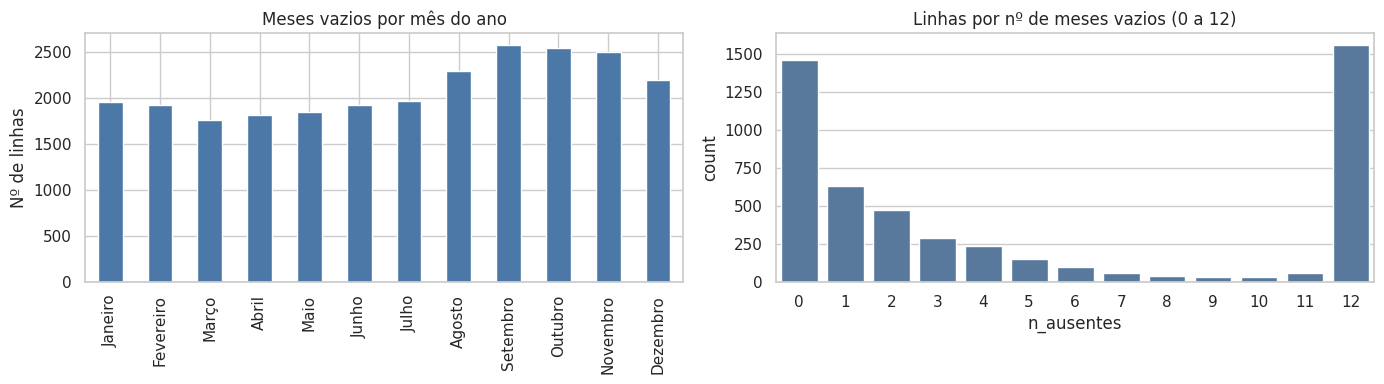

Linhas com os 12 meses vazios: 1562 (31%)


In [20]:
df['n_ausentes'] = df[MESES].isna().sum(axis=1)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df[MESES].isna().sum().plot(kind='bar', ax=ax[0], color='#4C78A8')
ax[0].set_title("Meses vazios por mês do ano"); ax[0].set_ylabel("Nº de linhas")
sns.countplot(x='n_ausentes', data=df, ax=ax[1], color='#4C78A8')
ax[1].set_title("Linhas por nº de meses vazios (0 a 12)")
plt.tight_layout(); plt.show()

print(f"Linhas com os 12 meses vazios: {(df['n_ausentes'] == 12).sum()} "
      f"({(df['n_ausentes'] == 12).mean():.0%})")

**Leitura:** o segundo semestre tem mais falhas, e cerca de **31% das linhas estão totalmente vazias**. Preencher uma linha inteira com a mediana não seria dado, e sim invenção. Por isso vamos **testar** dois cenários nos experimentos: manter todas as linhas, ou descartar as que têm **mais de 6 meses vazios**.

## 3. Atributos, alvo e validação

**Atributos (X):** os 12 totais mensais de chuva → **12 atributos** (o projeto exige 10 ou mais).
**Alvo (y):** a mesorregião. Ela **não** entra como atributo: seria dar a resposta ao modelo (vazamento).
**O ano não é atributo:** não indica a região.

**Grupos:** o mesmo posto aparece em vários anos. Se o posto A estivesse no treino em 2010 e no teste em 2011, o KNN o "reconheceria" e a acurácia ficaria inflada. Por isso usamos `StratifiedGroupKFold`, que:
- **agrupa por posto** (`Código`): um posto fica inteiro no treino ou inteiro no teste;
- **estratifica**: mantém a proporção das classes em cada fold;
- usa **seed fixa** (42) para reproduzir.

In [21]:
dados = df.dropna(subset=['Mesorregiao'])
X = dados[MESES].copy()
y = dados['Mesorregiao'].copy()
g = dados['Código'].copy()          # grupo = posto

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
print(f"Instâncias: {len(X)} | Atributos: {X.shape[1]} | Classes: {y.nunique()}")

def filtrar(X, y, g, max_aus):
    # descarta linhas com mais de max_aus meses vazios (None = mantém tudo)
    if max_aus is None:
        return X, y, g
    ok = X.isna().sum(axis=1) <= max_aus
    return X[ok], y[ok], g[ok]

Instâncias: 5104 | Atributos: 12 | Classes: 5


## 4. Pipeline e baseline

**O que fazemos:** montamos um `Pipeline` com três passos: **imputar → normalizar → KNN**.

**Por quê:** o pipeline é refeito **só com os dados de treino** a cada fold. Se preenchêssemos os vazios ou normalizássemos antes de dividir, o teste "vazaria" informação para o treino.

- **Imputação:** mediana (simples) ou KNNImputer (usa vizinhos).
- **Normalização:** o KNN usa distância; escalas diferentes a distorcem. Aqui todos os atributos já estão em mm, então o efeito do scaler tende a ser pequeno.
- **Métrica principal: F1 macro.** Como as classes são desbalanceadas, a acurácia pode parecer boa errando a classe pequena. O F1 macro dá o mesmo peso a cada uma das 5 classes.

In [22]:
IMPUTADORES = {'mediana': lambda: SimpleImputer(strategy='median'),
               'knn_imputer': lambda: KNNImputer(n_neighbors=5)}
SCALERS = {'standard': StandardScaler, 'minmax': MinMaxScaler, 'robust': RobustScaler}

def montar_pipe(imp, sc, k, w, met):
    return Pipeline([('imputer', IMPUTADORES[imp]()),
                     ('scaler', SCALERS[sc]()),
                     ('knn', KNeighborsClassifier(n_neighbors=k, weights=w, metric=met))])

SCORING = ['accuracy', 'balanced_accuracy', 'f1_macro']

# Baseline: configuração simples, só para ter uma referência
Xb, yb, gb = filtrar(X, y, g, 6)
r = cross_validate(montar_pipe('mediana', 'standard', 5, 'uniform', 'euclidean'),
                   Xb, yb, groups=gb, cv=cv, scoring=SCORING, n_jobs=-1)
print(f"Baseline (mediana, standard, k=5, uniform, euclidiana, ≤6 ausentes) "
      f"com {len(Xb)} instâncias:")
print(f"  acurácia   = {r['test_accuracy'].mean():.3f}")
print(f"  F1 macro   = {r['test_f1_macro'].mean():.3f} (± {r['test_f1_macro'].std():.3f})")

Baseline (mediana, standard, k=5, uniform, euclidiana, ≤6 ausentes) com 3337 instâncias:
  acurácia   = 0.687
  F1 macro   = 0.646 (± 0.011)


## 5. Os 360 experimentos

**O que fazemos:** uma **busca em grade** (grid search): testamos todas as combinações abaixo, cada uma com validação cruzada de 5 folds.

| Parâmetro | Valores | Quantidade |
|---|---|---|
| Limite de meses vazios por linha | sem limite · no máximo 6 | 2 |
| Imputação | mediana · KNNImputer | 2 |
| Normalização | Standard · MinMax · Robust | 3 |
| k (vizinhos) | 1, 3, 5, 7, 9 | 5 |
| Peso dos vizinhos | uniforme · por distância | 2 |
| Distância | euclidiana · Manhattan · Chebyshev | 3 |

2 × 2 × 3 × 5 × 2 × 3 = **360** (o requisito pedia 150 ou mais).

In [9]:
KS = [1, 3, 5, 7, 9]
PESOS = ['uniform', 'distance']
METRICAS = ['euclidean', 'manhattan', 'chebyshev']
MAX_AUSENTES = [None, 6]

if RODAR_GRADE:
    combos = list(itertools.product(MAX_AUSENTES, IMPUTADORES, SCALERS, KS, PESOS, METRICAS))
    print("Total de experimentos:", len(combos))
    linhas, cache = [], {}
    for i, (ma, imp, sc, k, w, met) in enumerate(combos, 1):
        if ma not in cache:
            cache[ma] = filtrar(X, y, g, ma)
        Xf, yf, gf = cache[ma]
        r = cross_validate(montar_pipe(imp, sc, k, w, met), Xf, yf, groups=gf, cv=cv,
                           scoring=SCORING, n_jobs=-1)
        linhas.append(dict(id=i, max_ausentes=ma, n_instancias=len(Xf), imputador=imp,
                           scaler=sc, k=k, pesos=w, metrica=met,
                           acc=r['test_accuracy'].mean(),
                           bal_acc=r['test_balanced_accuracy'].mean(),
                           f1_macro=r['test_f1_macro'].mean(),
                           f1_std=r['test_f1_macro'].std()))
        if i % 30 == 0:
            print(f"  {i}/{len(combos)} concluídos")
    res = pd.DataFrame(linhas)
else:
    res = pd.read_csv("https://raw.githubusercontent.com/mateuscresp/CienciaDados-Equipe5-Projeto/"
                      "main/results/experimentos_knn.csv")

res = res.sort_values('f1_macro', ascending=False).reset_index(drop=True)
print("Experimentos:", len(res))

Total de experimentos: 360
  30/360 concluídos
  60/360 concluídos
  90/360 concluídos
  120/360 concluídos
  150/360 concluídos
  180/360 concluídos
  210/360 concluídos
  240/360 concluídos
  270/360 concluídos
  300/360 concluídos
  330/360 concluídos
  360/360 concluídos
Experimentos: 360


## 6. Resultados

In [10]:
res['limite_ausentes'] = res['max_ausentes'].apply(lambda v: 'sem limite' if pd.isna(v) else f'≤ {int(v)}')
res.head(10)[['n_instancias', 'limite_ausentes', 'imputador', 'scaler', 'k', 'pesos',
              'metrica', 'acc', 'bal_acc', 'f1_macro', 'f1_std']].round(3)

,n_instancias,limite_ausentes,imputador,scaler,k,pesos,metrica,acc,bal_acc,f1_macro,f1_std
0,3337,≤ 6,mediana,minmax,9,distance,manhattan,0.744,0.712,0.711,0.028
1,3337,≤ 6,mediana,robust,5,distance,manhattan,0.731,0.718,0.709,0.024
2,3337,≤ 6,knn_imputer,minmax,3,distance,manhattan,0.730,0.723,0.709,0.025
3,3337,≤ 6,mediana,minmax,3,distance,manhattan,0.728,0.718,0.708,0.031
4,3337,≤ 6,mediana,robust,7,distance,manhattan,0.739,0.712,0.708,0.024
5,3337,≤ 6,mediana,standard,9,distance,manhattan,0.744,0.707,0.707,0.033
6,3337,≤ 6,knn_imputer,standard,7,distance,manhattan,0.732,0.717,0.707,0.021
7,3337,≤ 6,knn_imputer,standard,3,distance,manhattan,0.729,0.719,0.706,0.025
8,3337,≤ 6,knn_imputer,standard,9,distance,manhattan,0.731,0.711,0.706,0.013
9,3337,≤ 6,knn_imputer,robust,7,distance,manhattan,0.730,0.713,0.705,0.024


**Efeito de cada parâmetro no F1 macro** (média de todos os experimentos; a barra de erro é o desvio-padrão):

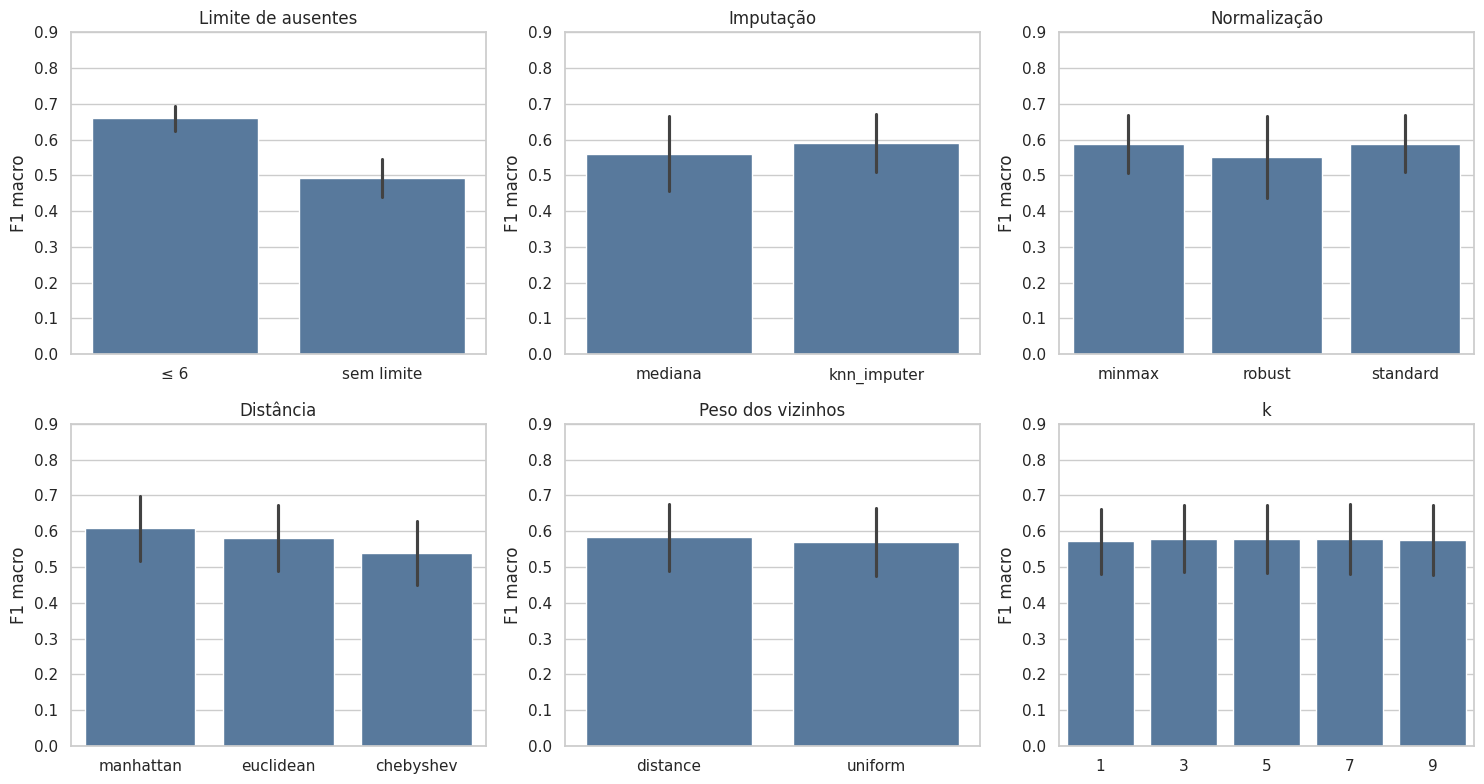

In [11]:
fatores = [('limite_ausentes', 'Limite de ausentes'), ('imputador', 'Imputação'),
           ('scaler', 'Normalização'), ('metrica', 'Distância'),
           ('pesos', 'Peso dos vizinhos'), ('k', 'k')]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (col, titulo) in zip(axes.ravel(), fatores):
    sns.barplot(data=res, x=col, y='f1_macro', errorbar='sd', ax=ax, color='#4C78A8')
    ax.set_title(titulo); ax.set_xlabel(''); ax.set_ylabel('F1 macro'); ax.set_ylim(0, 0.9)
plt.tight_layout(); plt.show()

**Como ler:**
- **Descartar linhas com mais de 6 meses vazios** é o fator que mais pesa. *Cuidado:* os dois grupos usam bases de tamanhos diferentes (5.104 contra ~3.300 linhas), então a comparação não é direta. O ponto é que imputar linhas totalmente vazias só inventa dado.
- A **distância Manhattan** costuma ir melhor: ela soma diferenças absolutas e é menos sensível a meses extremos (acima de 600 mm).
- **k, o scaler e o peso** mudam pouco. Isso é coerente: os 12 atributos já estão na mesma unidade (mm).
- As melhores configurações **diferem muito pouco entre si** (menos que o desvio entre folds): não existe "a" melhor, e sim um grupo equivalente.

## 7. Melhor modelo e onde ele erra

Refazemos a validação cruzada com a melhor configuração para ver o desempenho **por classe** e a **matriz de confusão**.

In [12]:
melhor = res.iloc[0]
print("Melhor configuração:")
print(melhor[['limite_ausentes', 'imputador', 'scaler', 'k', 'pesos', 'metrica',
              'n_instancias', 'acc', 'f1_macro']].to_string())

ma = None if pd.isna(melhor['max_ausentes']) else int(melhor['max_ausentes'])
Xm, ym, gm = filtrar(X, y, g, ma)
pipe = montar_pipe(melhor['imputador'], melhor['scaler'], int(melhor['k']),
                   melhor['pesos'], melhor['metrica'])
pred = cross_val_predict(pipe, Xm, ym, groups=gm, cv=cv, n_jobs=-1)

classes = sorted(ym.unique())
print()
print(classification_report(ym, pred, labels=classes, digits=3))

Melhor configuração:
limite_ausentes          ≤ 6
imputador            mediana
scaler                minmax
k                          9
pesos               distance
metrica            manhattan
n_instancias            3337
acc                 0.744475
f1_macro            0.711389

                            precision    recall  f1-score   support

      Agreste Pernambucano      0.763     0.825     0.793      1140
         Mata Pernambucana      0.747     0.704     0.725       726
   Metropolitana do Recife      0.814     0.787     0.801       367
       Sertão Pernambucano      0.716     0.783     0.748       774
São Francisco Pernambucano      0.638     0.421     0.507       330

                  accuracy                          0.745      3337
                 macro avg      0.736     0.704     0.715      3337
              weighted avg      0.742     0.745     0.740      3337



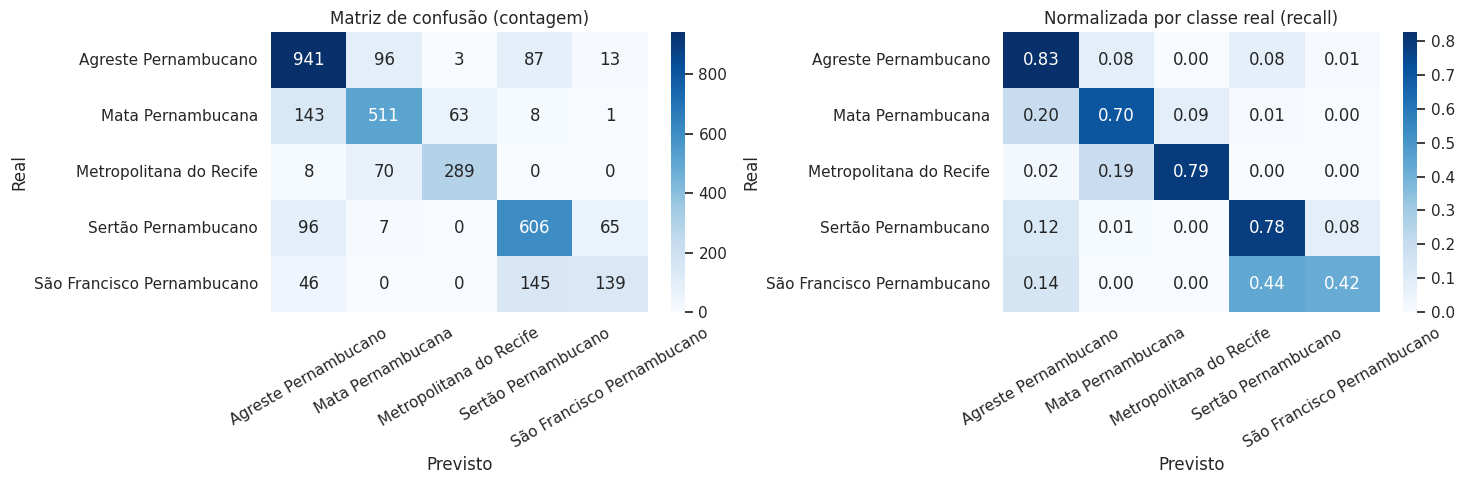

In [13]:
cm = pd.DataFrame(confusion_matrix(ym, pred, labels=classes), index=classes, columns=classes)
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax[0])
ax[0].set_title('Matriz de confusão (contagem)')
sns.heatmap(cm.div(cm.sum(axis=1), axis=0), annot=True, fmt='.2f', cmap='Blues', ax=ax[1])
ax[1].set_title('Normalizada por classe real (recall)')
for a in ax:
    a.set_xlabel('Previsto'); a.set_ylabel('Real'); a.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

**Como ler:** a diagonal são os acertos. O ponto mais fraco é o **São Francisco Pernambucano**, que muitas vezes é classificado como **Sertão**: são regiões vizinhas e de clima semiárido, com perfis de chuva parecidos. Metropolitana do Recife e Mata, de clima mais úmido, são mais fáceis de separar.

In [14]:
ok = lambda c: "OK" if c else "FALTA"
print("Requisitos do projeto")
print(f"  10 atributos ou mais : {X.shape[1]} atributos            -> {ok(X.shape[1] >= 10)}")
print(f"  1000 instâncias ou mais: {len(X)} (base completa), {len(Xm)} (melhor modelo) -> {ok(len(Xm) >= 1000)}")
print(f"  150 experimentos     : {len(res)} experimentos        -> {ok(len(res) >= 150)}")

Requisitos do projeto
  10 atributos ou mais : 12 atributos            -> OK
  1000 instâncias ou mais: 5104 (base completa), 3337 (melhor modelo) -> OK
  150 experimentos     : 360 experimentos        -> OK


## 8. Conclusões e limitações

**Conclusões**
- Só pelo perfil de chuva mensal, o KNN classifica a mesorregião com **F1 macro em torno de 0,72–0,73** e acurácia de cerca de 0,75 (validando por posto).
- O maior ganho veio de **tratar os dados ausentes**: descartar linhas quase ou totalmente vazias.
- A **distância Manhattan** e o **peso por distância** ficaram no grupo de cima; k entre 3 e 7 é equivalente.

**Limitações**
- Os melhores modelos diferem menos do que o desvio entre folds; o resultado também varia um pouco com a versão do scikit-learn (os folds mudam). Por isso reportamos média e desvio.
- O São Francisco tem poucos dados (~8%) e se confunde com o Sertão.
- Assumimos que "-" é "sem medição"; se for "zero chuva", o tratamento mudaria.
- O KNN só reconhece padrões parecidos com os do histórico.

**Próximos passos**
- Balanceamento das classes (por exemplo `class_weight` ou SMOTE) para melhorar o São Francisco.
- Seleção de atributos (por exemplo, remover os meses com mais ausências).
- Testar outros limites de ausentes (4, 8, 10).